# 25. Analytical chemistry: a calibration curve and its detection limit

**Track:** core example &nbsp;·&nbsp; **Uses:** Chapters 3, 8 and 11

**Reading:** Taylor, ch. 8 · Miller & Miller, *Statistics and Chemometrics
for Analytical Chemistry*, ch. 5 · Currie (1968) · ISO 11843-2

Most chemical analyses do not measure a concentration directly. An
instrument produces a signal (an absorbance, a peak area, a current), and a
**calibration curve** made with standards of known concentration converts the
signal of an unknown sample into a concentration. This example works
through the two questions every analytical report must answer:

1. What is the uncertainty of a concentration read off a calibration line?
2. What is the smallest concentration the method can detect, and what does
   "not detected" mean?

The second question has a precise answer, due to Currie (1968), that is
often replaced by a rule of thumb with very different properties.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(129)

## The experiment

Seven standards from 0 to 10 µg/L are each measured three times; the
standard at 0 µg/L is the *blank*. The noise of the signal is the same at
all concentrations, a common situation near the low end of a method's range.
Unknown samples are later measured three times each, and the mean signal is
used.

The next cell is the "apparatus". Skip it on first reading.

In [2]:
# ---- hidden truth of the simulated experiment --------------------------------
a_true, b_true, sigma_true = 2.0, 1.5, 0.8          # signal = a + b * concentration + noise
x_std = np.repeat([0.0, 1, 2, 4, 6, 8, 10], 3)       # µg/L
m_rep = 3                                            # replicates of an unknown

def calibrate(rng):
    return a_true + b_true * x_std + rng.normal(0, sigma_true, x_std.size)

def measure(x, rng, m=m_rep):
    return np.mean(a_true + b_true * x + rng.normal(0, sigma_true, m))
# ------------------------------------------------------------------------------

y_std = calibrate(rng)

## Step 1. The calibration line

The standards are fitted by an unweighted straight line. The noise level is
not known beforehand, so it is estimated from the residuals, $s$, with
$\nu = N - 2 = 19$ degrees of freedom (Section 11.2).

In [3]:
fit = ep.linear_fit(x_std, y_std)
N = x_std.size
resid = y_std - (fit.intercept + fit.slope * x_std)
s = np.sqrt(np.sum(resid**2) / (N - 2))
fit = ep.linear_fit(x_std, y_std, np.full(N, s))      # refit with the estimated sigma for the covariance
nu = N - 2
print(f"intercept a = {fit.intercept:.3f} ± {fit.u_intercept:.3f}   (true {a_true})")
print(f"slope     b = {fit.slope:.4f} ± {fit.u_slope:.4f}   (true {b_true})")
print(f"residual standard deviation s = {s:.3f} (true {sigma_true}), nu = {nu}")
print(f"correlation of a and b: {fit.correlation:+.2f}")

intercept a = 1.839 ± 0.288   (true 2.0)
slope     b = 1.5323 ± 0.0513   (true 1.5)
residual standard deviation s = 0.813 (true 0.8), nu = 19
correlation of a and b: -0.79


## Step 2. Reading a concentration off the line

An unknown gives a mean signal $\bar y_0$ from $m$ replicates. Its
concentration is $\hat x_0 = (\bar y_0 - a)/b$. Three quantities are
uncertain: $\bar y_0$, $a$ and $b$, and $a$ and $b$ are correlated. Linear
propagation with the full covariance (Section 12.1) gives the classical
result (Draper & Smith 1998; Miller & Miller, ch. 5.6)

$$ u(\hat x_0) = \frac{s}{b}\sqrt{\frac1m + \frac1N + \frac{(\bar y_0 - \bar y)^2}{b^2 \sum_i (x_i - \bar x)^2}} . $$

The three terms are the noise of the unknown's own readings, the
uncertainty of the calibration line's level, and that of its slope, which
grows with the distance from the centre of the calibration data. Since
$s$ is estimated with $\nu$ degrees of freedom, an interval with a given
coverage uses the $t$ factor $t_\nu$ (Section 4.4).

In [4]:
Sxx = np.sum((x_std - x_std.mean())**2)

def inverse_prediction(y0, fit, s, m=m_rep):
    x0 = (y0 - fit.intercept) / fit.slope
    u = s / fit.slope * np.sqrt(1 / m + 1 / N + (y0 - y_std.mean())**2 / (fit.slope**2 * Sxx))
    return x0, u

for x_unknown in (0.5, 5.0, 9.5):
    y0 = measure(x_unknown, rng)
    x0, u = inverse_prediction(y0, fit, s)
    # the same by general propagation through ep.propagate
    f = lambda y, a, b: (y - a) / b
    cov = np.zeros((3, 3)); cov[0, 0] = s**2 / m_rep; cov[1:, 1:] = fit.cov
    x0_p, u_p = ep.propagate(f, [y0, fit.intercept, fit.slope], cov=cov)
    print(f"true {x_unknown:4.1f} µg/L: x0 = {x0:5.2f} ± {u:.2f} µg/L   (ep.propagate: ± {float(np.squeeze(u_p)):.2f})")

true  0.5 µg/L: x0 =  0.83 ± 0.35 µg/L   (ep.propagate: ± 0.35)
true  5.0 µg/L: x0 =  5.14 ± 0.33 µg/L   (ep.propagate: ± 0.33)
true  9.5 µg/L: x0 =  9.74 ± 0.37 µg/L   (ep.propagate: ± 0.37)


The general propagation and the classical formula agree, as they must; the
formula is simply the propagation written out. The uncertainty is about
0.35 µg/L, dominated by the replicate noise of the unknown, and it grows
slowly towards the ends of the range. A coverage check over 20 000 repeated
calibrations confirms the stated intervals.

In [5]:
def calibrate_many(n, rng):
    """n independent calibrations at once: intercepts, slopes and residual sd (closed-form least squares)."""
    Y = a_true + b_true * x_std + rng.normal(0, sigma_true, (n, x_std.size))
    slope = ((x_std - x_bar) * (Y - Y.mean(axis=1, keepdims=True))).sum(axis=1) / Sxx
    icpt = Y.mean(axis=1) - slope * x_bar
    sd = np.sqrt(((Y - icpt[:, None] - slope[:, None] * x_std)**2).sum(axis=1) / nu)
    return icpt, slope, sd, Y.mean(axis=1)

def measure_many(x, n, rng):
    return a_true + b_true * x + rng.normal(0, sigma_true / np.sqrt(m_rep), n)

x_bar = x_std.mean()
t68 = stats.t.ppf(0.5 + 0.6827 / 2, nu)
icpt, slope, sd, ybar = calibrate_many(20000, rng)
print(f"t factor for 68.3 % with nu = {nu}: {t68:.3f}")
for x in (0.5, 5.0, 9.5):
    y0 = measure_many(x, icpt.size, rng)
    x0 = (y0 - icpt) / slope
    u = sd / slope * np.sqrt(1 / m_rep + 1 / N + (y0 - ybar)**2 / (slope**2 * Sxx))
    print(f"true {x:4.1f} µg/L: interval x0 ± t*u covers the truth in {np.mean(np.abs(x0 - x) < t68 * u):.3f}"
          f" of {icpt.size} trials (x0 ± u alone: {np.mean(np.abs(x0 - x) < u):.3f})")

t factor for 68.3 % with nu = 19: 1.027
true  0.5 µg/L: interval x0 ± t*u covers the truth in 0.679 of 20000 trials (x0 ± u alone: 0.667)
true  5.0 µg/L: interval x0 ± t*u covers the truth in 0.676 of 20000 trials (x0 ± u alone: 0.663)
true  9.5 µg/L: interval x0 ± t*u covers the truth in 0.678 of 20000 trials (x0 ± u alone: 0.666)


## Step 3. Decision threshold and detection limit

A sample with no analyte still gives a nonzero estimate $\hat x_0$, because
of noise. To decide whether the analyte is present, one compares $\hat x_0$
with a threshold, and two kinds of error are possible (Section 8.1):

* a **false positive** (type I): declaring a blank "detected";
* a **false negative** (type II): declaring a sample with analyte "not
  detected".

Currie (1968) separated the two questions with two quantities.

* The **decision threshold** (critical value) $x_C$ is chosen so that a
  blank exceeds it with probability $\alpha$, usually 5 %. It is a property
  of the *measurement result*: $\hat x_0 > x_C$ means "detected".
* The **detection limit** $x_D$ is the true concentration that is detected
  with probability $1 - \beta$, usually 95 %. It is a property of the
  *method*, used to decide whether a method is fit for a purpose.

With the standard uncertainty of $\hat x_0$ at zero concentration,
$u_0 = (s/b)\sqrt{1/m + 1/N + \bar x^2/\sum(x_i - \bar x)^2}$, and $s$ estimated
with $\nu$ degrees of freedom (ISO 11843-2):

$$ x_C = t_{1-\alpha,\nu}\,u_0 , \qquad x_D \approx (t_{1-\alpha,\nu} + t_{1-\beta,\nu})\,u_0 \approx 2 x_C . $$

The second expression is a good approximation; the exact factor uses the
noncentral $t$ distribution. A popular rule of thumb instead defines a
"limit of detection" as $3s/b$ and reports any result below it as "not
detected". The simulation below compares the two, applying the full
procedure, calibration included, 20 000 times.

In [6]:
alpha = beta = 0.05
t_a, t_b = stats.t.ppf(1 - alpha, nu), stats.t.ppf(1 - beta, nu)
k0 = np.sqrt(1 / m_rep + 1 / N + x_bar**2 / Sxx)        # u0 = (s/b) * k0

def thresholds(intercept, slope, s):
    u0 = s / slope * k0
    return t_a * u0, (t_a + t_b) * u0, 3 * s / slope

xC, xD, x3s = thresholds(fit.intercept, fit.slope, s)
print(f"this calibration: decision threshold x_C = {xC:.2f} µg/L, detection limit x_D = {xD:.2f} µg/L, "
      f"rule of thumb 3s/b = {x3s:.2f} µg/L")

xD_true = (t_a + t_b) * sigma_true / b_true * k0
levels = np.array([0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0])
p_currie, p_rule = [], []
n_sim = 20000
for x in levels:
    icpt, slope, sd, _ = calibrate_many(n_sim, rng)       # a fresh calibration for every trial
    x0 = (measure_many(x, n_sim, rng) - icpt) / slope
    c, _, r = thresholds(icpt, slope, sd)
    p_currie.append(np.mean(x0 > c)); p_rule.append(np.mean(x0 > r))
p_currie, p_rule = np.array(p_currie), np.array(p_rule)
print(f"\ndetection limit for the true sigma: x_D = {xD_true:.2f} µg/L;  3*sigma/b = {3 * sigma_true / b_true:.2f} µg/L")
print("true conc.   P(detected), Currie x_C    P(detected), 3s/b rule")
for x, pc, pr in zip(levels, p_currie, p_rule):
    print(f"  {x:4.2f}            {pc:.3f}                   {pr:.3f}")
xd_c = np.interp(0.95, p_currie, levels); xd_r = np.interp(0.95, p_rule, levels)
print(f"concentration detected with 95 % probability: Currie {xd_c:.2f} µg/L, rule of thumb {xd_r:.2f} µg/L")

this calibration: decision threshold x_C = 0.62 µg/L, detection limit x_D = 1.24 µg/L, rule of thumb 3s/b = 1.59 µg/L

detection limit for the true sigma: x_D = 1.25 µg/L;  3*sigma/b = 1.60 µg/L
true conc.   P(detected), Currie x_C    P(detected), 3s/b rule
  0.00            0.052                   0.000
  0.25            0.165                   0.001
  0.50            0.378                   0.006
  0.75            0.643                   0.030
  1.00            0.847                   0.097
  1.25            0.952                   0.229
  1.50            0.991                   0.435
  1.75            0.999                   0.649
  2.00            1.000                   0.832
  2.50            1.000                   0.980
  3.00            1.000                   0.999
concentration detected with 95 % probability: Currie 1.25 µg/L, rule of thumb 2.40 µg/L


The simulation confirms Currie's construction. Blanks are declared
"detected" at close to the intended 5 %, and a sample at the detection
limit (here about 1.25 µg/L in true concentration) is detected about 95 % of
the time. The rule of thumb behaves quite differently: it almost never gives
a false positive, but a sample at its own "limit of detection", $3s/b
\approx 1.6$ µg/L, is detected only about half the time, and the
concentration detected with 95 % probability is near 2.4 µg/L, twice the
detection limit. The rule
confuses a decision threshold with a detection limit. Neither is wrong as a
number, but reporting "not detected (< 3s/b)" implies a 50 % chance that
a sample at that level was missed.

Three practical points follow.

* Report the decision threshold and the detection limit separately, with
  $\alpha$, $\beta$ and the number of replicates.
* Report measured values even when they fall below the threshold, with their
  uncertainty, including negative values. Replacing them by "< LOD" or by
  zero biases any later average.
* The detection limit depends on the replicates of the unknown ($m$), on the
  calibration design ($N$, $\bar x$), and above all on the noise at low
  concentration. Calibrating with standards concentrated near the low end
  reduces $\bar x$ and therefore $u_0$.

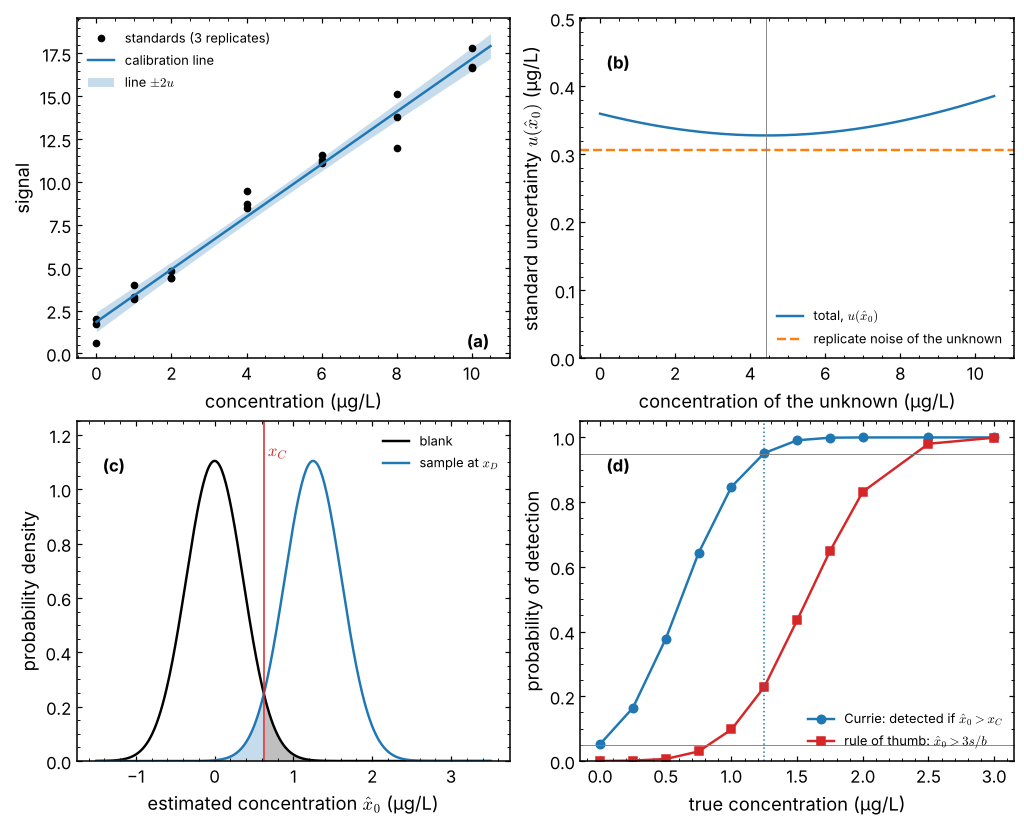

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
xf = np.linspace(0, 10.5, 200)
ax.plot(x_std, y_std, "o", ms=4, color="k", label="standards (3 replicates)")
ax.plot(xf, fit.intercept + fit.slope * xf, "C0", label="calibration line")
band = s * np.sqrt(1 / N + (xf - x_bar)**2 / Sxx)
ax.fill_between(xf, fit.intercept + fit.slope * xf - 2 * band, fit.intercept + fit.slope * xf + 2 * band,
                color="C0", alpha=0.25, lw=0, label=r"line $\pm 2u$")
ax.set_xlabel("concentration (µg/L)"); ax.set_ylabel("signal")
ax.legend(loc="upper left", fontsize=8.5); ep.panel_label(ax, "(a)", x=0.9, y=0.08)

ax = axes[0, 1]
y0_grid = fit.intercept + fit.slope * xf
u_grid = np.array([inverse_prediction(y, fit, s)[1] for y in y0_grid])
u_m = s / fit.slope / np.sqrt(m_rep)
ax.plot(xf, u_grid, "C0", label="total, $u(\\hat x_0)$")
ax.axhline(u_m, color="C1", ls="--", label="replicate noise of the unknown")
ax.axvline(x_bar, color="0.5", lw=0.6)
ax.set_xlabel("concentration of the unknown (µg/L)"); ax.set_ylabel(r"standard uncertainty $u(\hat x_0)$ (µg/L)")
ax.set_ylim(0, 0.5); ax.legend(loc="lower right", fontsize=8.5); ep.panel_label(ax, "(b)", x=0.06, y=0.9)

ax = axes[1, 0]
xx = np.linspace(-1.5, 3.5, 400)
u0_true = sigma_true / b_true * np.sqrt(1 / m_rep + 1 / N + x_bar**2 / Sxx)
ax.plot(xx, stats.norm.pdf(xx, 0, u0_true), "k", label="blank")
ax.plot(xx, stats.norm.pdf(xx, xD_true, u0_true), "C0", label="sample at $x_D$")
xC_true = stats.t.ppf(1 - alpha, nu) * u0_true
ax.fill_between(xx[xx > xC_true], stats.norm.pdf(xx[xx > xC_true], 0, u0_true), color="k", alpha=0.25, lw=0)
ax.fill_between(xx[xx < xC_true], stats.norm.pdf(xx[xx < xC_true], xD_true, u0_true), color="C0", alpha=0.25, lw=0)
ax.axvline(xC_true, color="C3", lw=1)
ax.text(xC_true + 0.05, 1.12, "$x_C$", color="C3")
ax.set_xlabel(r"estimated concentration $\hat x_0$ (µg/L)"); ax.set_ylabel("probability density")
ax.set_ylim(0, 1.25); ax.legend(loc="upper right", fontsize=8.5); ep.panel_label(ax, "(c)", x=0.06, y=0.9)

ax = axes[1, 1]
ax.plot(levels, p_currie, "o-", color="C0", label="Currie: detected if $\\hat x_0 > x_C$")
ax.plot(levels, p_rule, "s-", color="C3", label="rule of thumb: $\\hat x_0 > 3s/b$")
ax.axhline(0.95, color="0.5", lw=0.6); ax.axhline(0.05, color="0.5", lw=0.6)
ax.axvline(xD_true, color="C0", ls=":", lw=1)
ax.set_xlabel("true concentration (µg/L)"); ax.set_ylabel("probability of detection")
ax.set_ylim(0, 1.05); ax.legend(loc="lower right", fontsize=8.5); ep.panel_label(ax, "(d)", x=0.06, y=0.9)
plt.show()

**(a)** Calibration data with the fitted line and a band of $\pm 2$ standard
uncertainties of the line. **(b)** Standard uncertainty of a concentration
read off the line, against the concentration; it is smallest at the centre
of the calibration (vertical line) and never below the replicate noise of
the unknown (dashed). **(c)** Distributions of the estimate for a blank and
for a sample at the detection limit: the shaded tails are the false-positive
and false-negative rates, both about 5 %. **(d)** Probability of detection against
true concentration for the two decision rules; dotted: $x_D$.

## What this example teaches

* The uncertainty of a value read off a calibration line combines the
  unknown's own noise with the uncertainty of the line, including the
  correlation of intercept and slope; it is linear propagation written out.
* Use the $t$ factor when the noise is estimated from the calibration.
* Detection involves two error rates and two quantities: a decision
  threshold for results and a detection limit for methods. A single "3s"
  number cannot serve as both.

## References

* L. A. Currie, "Limits for qualitative detection and quantitative
  determination. Application to radiochemistry", *Anal. Chem.* **40**, 586
  (1968).
* N. R. Draper and H. Smith, *Applied Regression Analysis*, 3rd ed. (Wiley,
  1998).
* ISO 11843-2:2000, *Capability of detection — Part 2: Methodology in the
  linear calibration case* (International Organization for Standardization,
  Geneva).
* J. N. Miller and J. C. Miller, *Statistics and Chemometrics for Analytical
  Chemistry*, 6th ed. (Pearson, 2010).

## Exercises

1. Move four of the seven standards to 0, 0.5, 1 and 1.5 µg/L, keeping the
   total number of measurements. How do $x_C$, $x_D$ and the uncertainty at
   9.5 µg/L change?
2. Make the noise proportional to the signal above 5 µg/L and refit with
   weights (Section 11.4). Which conclusions change?
3. Show that, for $\alpha = \beta$ and constant noise, $x_D = 2x_C$ when
   $\sigma$ is known.
4. Average 50 simulated results for a sample at 0.5 µg/L twice: once as
   reported, and once with every result below $x_C$ replaced by zero.
   Compare both averages with the truth.

---

**Previous:** [24. Nuclear physics: a half-life from decay counts](24_radioactive_decay_counts.ipynb) &nbsp;·&nbsp; **Next:** [26. Mechanical engineering: tolerance stack-up and inspection](26_tolerance_stack_up.ipynb)